In [4]:
# k means algorithm---
# sns dataset used
# find similar observations and group them together_cluster


In [5]:
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings("ignore")

In [6]:
sns=pd.read_csv(r"C:\Users\krish\Downloads\snsdata.csv")

In [7]:
sns

,gradyear,gender,age,friends,basketball,football,soccer,softball,volleyball,swimming,...,blonde,mall,shopping,clothes,hollister,abercrombie,die,death,drunk,drugs
0,2006,M,18.982,7,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2006,F,18.801,0,0,1,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
2,2006,M,18.335,69,0,1,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
3,2006,F,18.875,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,2006,NaN,18.995,10,0,0,0,0,0,0,...,0,0,2,0,0,0,0,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,2009,M,16.115,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
29996,2009,M,15.792,1,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
29997,2009,M,15.784,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
29998,2009,M,16.378,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [8]:
sns.isnull().sum()[sns.isnull().sum()>0]

gender    2724
age       5086
dtype: int64

In [17]:
# filling nulls of gender -- with mode
sns['gender']=sns['gender'].fillna(sns['gender'].mode()[0])

In [18]:
# filling nulls of age-- with median
sns['age']=sns['age'].fillna(sns['age'].median())

In [19]:
sns.isnull().sum()[sns.isnull().sum()>0]

Series([], dtype: int64)

In [20]:
from sklearn.preprocessing import LabelEncoder

In [21]:
le=LabelEncoder()

sns[sns.select_dtypes(include='object').columns] = sns[sns.select_dtypes(include='object').columns].apply(le.fit_transform)

In [22]:
sns.columns

Index(['gradyear', 'gender', 'age', 'friends', 'basketball', 'football',
       'soccer', 'softball', 'volleyball', 'swimming', 'cheerleading',
       'baseball', 'tennis', 'sports', 'cute', 'sex', 'sexy', 'hot', 'kissed',
       'dance', 'band', 'marching', 'music', 'rock', 'god', 'church', 'jesus',
       'bible', 'hair', 'dress', 'blonde', 'mall', 'shopping', 'clothes',
       'hollister', 'abercrombie', 'die', 'death', 'drunk', 'drugs'],
      dtype='object')

In [23]:
sns.head()

,gradyear,gender,age,friends,basketball,football,soccer,softball,volleyball,swimming,...,blonde,mall,shopping,clothes,hollister,abercrombie,die,death,drunk,drugs
0,2006,1,18.982,7,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2006,0,18.801,0,0,1,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
2,2006,1,18.335,69,0,1,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
3,2006,0,18.875,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,2006,0,18.995,10,0,0,0,0,0,0,...,0,0,2,0,0,0,0,0,1,1


In [24]:
from sklearn.cluster import KMeans
kmean_sns=KMeans(n_clusters=4)

In [25]:
kmean_sns.fit(sns)

  File "C:\Users\krish\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\krish\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\krish\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\krish\anaconda3\Lib\subprocess.

KMeans(n_clusters=4)

In [26]:
kmean_sns.labels_

array([0, 0, 3, ..., 0, 0, 0], dtype=int32)

In [27]:
len(kmean_sns.labels_)

30000

In [28]:
pd.DataFrame(kmean_sns.labels_).value_counts()

0
0    16889
1     9253
3     3332
2      526
Name: count, dtype: int64

In [29]:
cluster_center=pd.DataFrame(kmean_sns.cluster_centers_)

In [30]:
cluster_center

,0,1,2,3,4,5,6,7,8,9,...,30,31,32,33,34,35,36,37,38,39
0,2007.443306,0.192433,17.978249,7.660015,0.229321,0.231985,0.197347,0.123335,0.115519,0.120197,...,0.081118,0.222452,0.302978,0.137427,0.054355,0.040322,0.178992,0.103973,0.084374,0.063473
1,2007.539707,0.163358,17.732336,41.326608,0.302870,0.274709,0.247410,0.200043,0.173932,0.153863,...,0.125701,0.279780,0.396849,0.161847,0.081355,0.058373,0.193893,0.128291,0.090419,0.057618
2,2007.775665,0.072243,17.581774,187.885932,0.389734,0.302281,0.264259,0.197719,0.222433,0.176806,...,0.153992,0.418251,0.536122,0.190114,0.131179,0.115970,0.212928,0.144487,0.131179,0.068441
3,2007.634007,0.126620,17.786250,88.685861,0.342177,0.285197,0.276756,0.239674,0.185107,0.145614,...,0.106120,0.347000,0.456135,0.160989,0.107024,0.075972,0.178173,0.122400,0.092554,0.051553


In [31]:
cluster_center.columns=sns.columns

In [32]:
cluster_center

,gradyear,gender,age,friends,basketball,football,soccer,softball,volleyball,swimming,...,blonde,mall,shopping,clothes,hollister,abercrombie,die,death,drunk,drugs
0,2007.443306,0.192433,17.978249,7.660015,0.229321,0.231985,0.197347,0.123335,0.115519,0.120197,...,0.081118,0.222452,0.302978,0.137427,0.054355,0.040322,0.178992,0.103973,0.084374,0.063473
1,2007.539707,0.163358,17.732336,41.326608,0.302870,0.274709,0.247410,0.200043,0.173932,0.153863,...,0.125701,0.279780,0.396849,0.161847,0.081355,0.058373,0.193893,0.128291,0.090419,0.057618
2,2007.775665,0.072243,17.581774,187.885932,0.389734,0.302281,0.264259,0.197719,0.222433,0.176806,...,0.153992,0.418251,0.536122,0.190114,0.131179,0.115970,0.212928,0.144487,0.131179,0.068441
3,2007.634007,0.126620,17.786250,88.685861,0.342177,0.285197,0.276756,0.239674,0.185107,0.145614,...,0.106120,0.347000,0.456135,0.160989,0.107024,0.075972,0.178173,0.122400,0.092554,0.051553


In [33]:
# kmeans model score
kmean_sns.score(sns)

-8122493.57501438

In [34]:
# negative score not good cluster

In [35]:
#Inertia measures the sum of squared distances between each data
#point and its assigned cluster center, quantifying how well the data points fit their respective clusters.

In [36]:
# Elbow method
# Elbow Method using SSD / Inertia

ssd = []
for k in range(1, 12):
    kmean_sns =KMeans(n_clusters=k, random_state=42)
    kmean_sns.fit(sns)
    ssd.append(kmean_sns.inertia_)

    print("Value of k is:", k)

Value of k is: 1
Value of k is: 2
Value of k is: 3
Value of k is: 4
Value of k is: 5
Value of k is: 6
Value of k is: 7
Value of k is: 8
Value of k is: 9
Value of k is: 10
Value of k is: 11


In [37]:
import matplotlib.pyplot as plt

In [38]:
import numpy as np

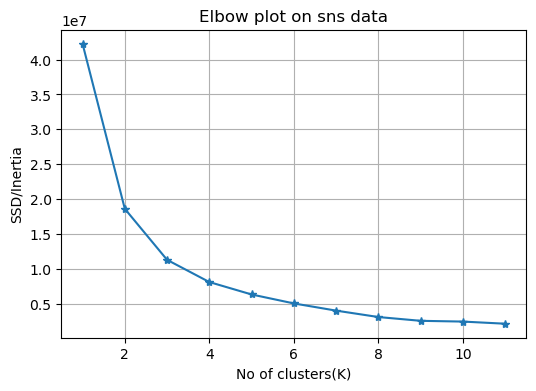

In [55]:
plt.figure(figsize=(6,4))
plt.plot(list(range(1,12)),ssd,marker='*')
plt.grid()
plt.title("Elbow plot on sns data")
plt.xlabel("No of clusters(K)")
plt.ylabel("SSD/Inertia")
plt.show()


In [40]:
from sklearn.cluster import KMeans
kmean_sns1=KMeans(n_clusters=6)
kmean_sns1.fit(sns)

KMeans(n_clusters=6)

In [41]:
kmean_sns1.score(sns)

-5295964.782594215

In [42]:
pd.Series(kmean_sns1.labels_).value_counts()

2    15194
0     8890
1     4318
5     1358
4      233
3        7
Name: count, dtype: int64

In [48]:
sns['Cluster_number']=kmean_sns1.labels_

In [49]:
sns.head(20)

,gradyear,gender,age,friends,basketball,football,soccer,softball,volleyball,swimming,...,mall,shopping,clothes,hollister,abercrombie,die,death,drunk,drugs,Cluster_number
0,2006,1,18.982,7,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,2
1,2006,0,18.801,0,0,1,0,0,0,0,...,1,0,0,0,0,0,0,0,0,2
2,2006,1,18.335,69,0,1,0,0,0,0,...,0,0,0,0,0,0,1,0,0,1
3,2006,0,18.875,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,2
4,2006,0,18.995,10,0,0,0,0,0,0,...,0,2,0,0,0,0,0,1,1,2
5,2006,0,17.287,142,0,0,0,0,0,0,...,0,1,0,0,0,0,0,1,0,5
6,2006,0,18.930,72,0,0,0,0,0,0,...,2,0,0,2,0,0,0,0,0,1
7,2006,1,18.322,17,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,2
8,2006,0,19.055,52,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
9,2006,0,18.708,39,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0


In [50]:
colormap=np.array(['red','green','blue','black','yellow','purple'])

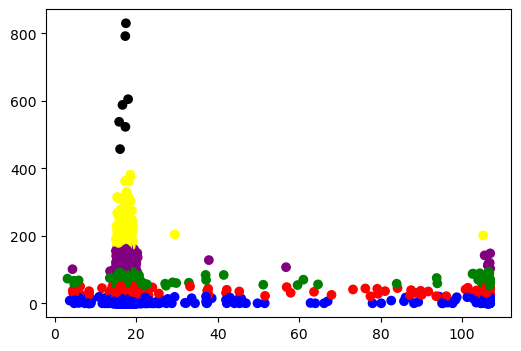

In [56]:
plt.figure(figsize=(6,4))
plt.scatter(sns.age,sns.friends,c=colormap[kmean_sns1.labels_])
plt.show()

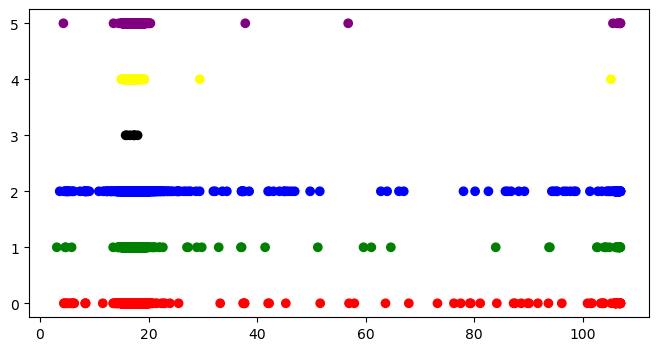

In [57]:
plt.figure(figsize=(8,4))
plt.scatter(sns.age,sns.Cluster_number,c=colormap[kmean_sns1.labels_])
plt.show()

In [ ]:
# I had data without a target variable, 
#so I used an unsupervised learning algorithm called K-Means to discover groups in the data.
#First, I cleaned the data by handling missing values.
#Then I encoded categorical variables into numerical values and scaled the features because K-Means is distance-based.
#I applied K-Means clustering, but first I tested different values of K using the Elbow Method.
#For each K, I calculated SSD/Inertia (WCSS). 
#I selected a suitable K from the elbow point,
#trained the final K-Means model, assigned each observation a cluster number, and then analyzed and visualized the resulting clusters.